# Igualar objetivos antes de comparar métodos

Nivel 3. Requisitos previos: precios escalares e integridad de control. Tiempo de lectura: 40 minutos.

**Pregunta:** ¿Qué solvers publicados concuerdan al recibir el mismo objetivo elástico o L1 y qué cambia cuando una familia de penalización es incompatible?


## Objetivos

Una comparación comienza por un contrato matemático. Igualar matrices y límites no basta si un método cobra cuadráticamente y otro usa restauración lineal. Son decisiones diferentes aunque ambas bibliotecas hablen de restricciones blandas. Por ello utilizaremos dos familias identificadas y compararemos métodos solo dentro de cada una. Cambiar de familia nunca se interpretará como mejorar precisión numérica.

La proyección generalizada publicada y DAQP cubren una instancia dispersa elástica simétrica. La proyección asimétrica, la reconstrucción FlexQP fija y el backend publicado ElastiQP cubren una instancia L1 con precios desiguales. Las holguras explícitas con OSQP independiente verifican cada familia. Buscamos entender concordancia, dimensiones y exactitud de penalización, sin trasladar a nuestra máquina la aceleración publicada de otro experimento.


## Preparación

Utilice un entorno separado de Python 3.12. El motor nativo es una distribución separada. Instale el entorno exacto fuera del cuaderno:

```bash
pip install "softqp==0.1.0"
pip install "numpy==2.5.4"
pip install "scipy==1.18.1"
pip install "matplotlib==3.11.2"
pip install "osqp==1.1.3"
pip install "daqp==0.10.3"
pip install "elastiqp==0.2.0"
```

La única celda de preparación localiza el repositorio, importa los métodos e imprime versiones numéricas. No se instala software dentro del kernel.


In [1]:
# Localizar entradas una vez deja las celdas científicas dedicadas a optimización.
from pathlib import Path
import sys
import json
import importlib.metadata
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from softqp.solvers import solve
from softqp.flex import solve_flex
from softqp.elasti import solve_elastiqp
candidates = [Path.cwd(), *Path.cwd().parents]
root = next(p for p in candidates if (p / "VERSION").is_file() and (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from pipeline.softqp_cases import scalar, mpc
from pipeline.softqp_campaign import generated_problem, primary_endpoint
from pipeline.optimality import kkt
for distribution in ("softqp", "numpy", "scipy", "matplotlib", "osqp", "daqp", "elastiqp"):
    print(distribution, importlib.metadata.version(distribution))
accurate = dict(eps_abs=1e-9, eps_rel=1e-9, adaptive_rho_interval=25)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})

# Los identificadores del solver se conservan; las figuras usan nombres en español.
method_labels = {
    'lifted': 'Holguras explícitas',
    'generalized': 'Proyección generalizada',
    'asymmetric': 'Proyección asimétrica',
    'daqp': 'DAQP',
    'flex': 'FlexQP',
    'elastiqp': 'ElastiQP',
}


softqp 0.1.0
numpy 2.5.4
scipy 1.18.1
matplotlib 3.11.2
osqp 1.1.3
daqp 0.10.3
elastiqp 0.2.0


## Datos

Usamos el generador del producto con semilla de desarrollo 1000, 32 variables, 64 filas, densidad 0.1 y condición diagonal unitaria. Las filas tienen norma euclidiana unitaria. La familia elástica simétrica conserva su máscara dura. La familia L1 declara todas las filas blandas y elimina el precio cuadrático: es otra política propia con los mismos parámetros generadores, no una relajación oculta del primer problema.

Son entradas educativas: no utilizan semillas reservadas ni ajustan parámetros numéricos registrados. El posterior barrido escalar aísla en una dimensión el umbral de penalización exacta.

Felipe Santibáñez-Leal elaboró estos problemas matemáticos y archivos de intercambio numérico bajo los términos MIT del producto, documentados en el [repositorio público](https://github.com/fsantibanezleal/CAOS_SoftQP). La lección lee índices científico y de despliegue, manifiesto C01, índice experimental, tabla de conjuntos y un ensayo JSONL desde sus rutas versionadas. Esos registros explican procedencia y valores ausentes; todos los puntos de comparación y las decisiones dibujadas se vuelven a calcular con los métodos siguientes.


In [2]:
# Leer un solo ensayo conserva pequeño el ejemplo de intercambio.
scientific_index = json.loads((root / "data/derived/softqp/index.json").read_text(encoding="utf-8"))
deployment_index = json.loads((root / "data/derived/manifests/index.json").read_text(encoding="utf-8"))
manifest_example = json.loads((root / "data/derived/manifests/C01.json").read_text(encoding="utf-8"))
experiment_index = json.loads((root / "data/derived/experiments/index.json").read_text(encoding="utf-8"))
datasets = json.loads((root / "data/derived/experiments/datasets.json").read_text(encoding="utf-8"))
with (root / "data/derived/experiments/trials.jsonl").open(encoding="utf-8") as trial_source:
    first_trial = json.loads(trial_source.readline())


## Método

Para precios elásticos simétricos, la proyección generalizada publicada cambia la operación proximal del intervalo manteniendo las dimensiones principales del QP. Una formulación explícita introduce variables auxiliares para representar el mismo costo. DAQP resuelve un conjunto activo dual y utiliza su convención recíproca de peso cuadrático. Estas diferencias algorítmicas deberían conservar el óptimo cuando coinciden objetivo convexo y política dura.

Primero ejecutamos la implementación fija de proyección generalizada de los autores. Aquí se cumplen sus supuestos simétricos. La extensión asimétrica es innecesaria en esta instancia y cambiar precios ocultaría la pregunta. Imprimimos dimensiones y objetivo original en vez de comparar convenciones internas de costo.


### Igualar la función antes de igualar la implementación

Sea $z=Ax$ el valor de fila en coordenadas originales. Para un intervalo $C_i=[l_i,u_i]$ definimos $r_i(z)=z_i-\Pi_{C_i}(z_i)$. Su magnitud es la distancia exterior y su signo identifica el lado. La proyección generalizada publicada combina proyección ordinaria y operación proximal del residuo:

$$T_i(v)=\Pi_{C_i}(v_i)+\operatorname{prox}_{\phi_i/\rho}\!\left(v_i-\Pi_{C_i}(v_i)\right),\qquad\rho>0.$$

Esta igualdad se usa bajo las hipótesis de penalización publicadas. En la familia elástica simétrica, $\phi_i(r)=a_i|r|+b_i r^2/2$, de modo que pendiente y curvatura coinciden a ambos lados. La extensión asimétrica utiliza otra operación proximal; promediar precios para ajustarse a esta expresión cambiaría la pregunta de optimización. El [artículo de proyecciones generalizadas](https://arxiv.org/abs/2610.35631) y la implementación nativa fijada son las fuentes de ese camino numérico.

El levantamiento explícito representa el mismo precio compatible mediante holguras inferiores y superiores no negativas. Sus desigualdades son $l-s_l\leq Ax\leq u+s_u$. Términos lineales y cuadráticos diagonales valoran las nuevas variables. El vector de decisiones crece, pero el resultado es admisible para OSQP convencional. El camino nativo conserva la estructura principal original. Ambos se juzgan con el evaluador original: comparar objetivos internos sin recuperar constantes omitidas y convenciones de holgura no demostraría equivalencia.

DAQP documenta el término cuadrático como $s^2/(2\rho_\mathrm{soft})$, mientras el coeficiente original del paquete es $b s^2/2$. El adaptador utiliza por ello pesos recíprocos, no un argumento numéricamente igual. Sus pesos lineales también conservan sentidos inferiores y superiores distintos. La [especificación de pesos blandos DAQP](https://darnstrom.github.io/daqp/start/advanced/soft) define esa correspondencia. La Hessiana definida positiva de nuestra instancia elástica permite el camino de conjunto activo; una sustitución semidefinida no hereda su aceptación sólo por mantener las dimensiones.

Para una familia puramente lineal escribimos las desigualdades admisibles como $Gx\leq h$, con precios positivos $w$. Tanto la reconstrucción fija de FlexQP como ElastiQP resuelven

$$\min_{x,s\geq0}\ \frac12x^\top Px+q^\top x+w^\top s\quad\text{con}\quad Gx-s\leq h.$$

Esta forma difiere del ejemplo elástico: los coeficientes blandos cuadráticos son cero y nuestra entrada de comparación no contiene desigualdades duras. Un lado ausente no genera una desigualdad finita ni una holgura inventada. FlexQP estabiliza sus sistemas numéricos mediante términos proximales, pero éstos no pasan a ser una regularización científica de este objetivo. ElastiQP utiliza su implementación publicada de conjunto activo. Después de ejecutar recuperamos duales y evaluamos el costo original; compartir una palabra como elástico no basta para atribuir semántica idéntica.

El origen de cada resultado permanece visible: la reconstrucción fija sigue las ecuaciones del artículo y no es el código liberado por sus autores. Tampoco usa la política neuronal de Deep FlexQP. La ausencia de pesos reproducibles no se soluciona asignando valores arbitrarios a una red ni interpretando el esquema fijo como una reproducción aprendida. Esta separación permite una comparación ejecutable sin ampliar injustificadamente la evidencia del producto.


In [3]:
# Esta familia satisface los supuestos publicados de penalización simétrica.
spec = dict(n=32, density=0.1, seed=1000, family="symmetric-elastic", condition=1)
elastic = generated_problem(spec)
settings = dict(eps_abs=1e-8, eps_rel=1e-8, max_iter=200000)
native_settings = dict(settings, adaptive_rho_interval=25)
generalized = solve(elastic, "generalized", **native_settings)
print("Generalizada:", generalized["dimensions"])
print(f"Objetivo elástico: {generalized['metrics']['objective']:.8f}")


Generalizada: {'variables': 32, 'rows': 64, 'nnz': 239}
Objetivo elástico: -44.95315486


La referencia de conjunto activo recibe coeficientes originales idénticos. La diagonal positiva y los precios cuadráticos elásticos satisfacen sus requisitos. Ante condiciones no admitidas corresponde un resultado incompatible, no insertar regularización en el objetivo. La distinción importa especialmente con hessianas semidefinidas o lados L1 puros de otros casos.


In [4]:
# DAQP participa porque coinciden definición positiva y costos elásticos.
daqp = solve(elastic, "daqp", **native_settings)
print("DAQP:", daqp["status"], daqp["dimensions"])
print(f"Objetivo elástico del conjunto activo: {daqp['metrics']['objective']:.8f}")


DAQP: soft optimal {'variables': 32, 'rows': 64, 'nnz': 239}
Objetivo elástico del conjunto activo: -44.95315485


Cerramos la primera comparación con holguras explícitas y OSQP estándar independiente. Una diferencia pequeña de objetivo respalda equivalencia en esta entrada. No demuestra equivalencia para todas las familias y contar variables no mide tiempo. Una factorización menor puede quedar compensada por validación, iteraciones o diferencias de lenguaje de implementación.


In [5]:
# Evaluar un QP formulado por separado antes de comparar dimensiones.
elastic_lift = solve(elastic, "lifted", **native_settings)
elastic_results = [elastic_lift, generalized, daqp]
for result in elastic_results:
    difference = abs(result["metrics"]["objective"] - elastic_lift["metrics"]["objective"])
    print(result["method"], f"brecha del objetivo {difference:.3e}", result["dimensions"]["variables"])


lifted brecha del objetivo 0.000e+00 84
generalized brecha del objetivo 1.310e-08 32
daqp brecha del objetivo 1.319e-10 32


## Comparación

Declaramos ahora un problema L1 puro, sin fingir que el objetivo elástico cabe en todas las bibliotecas. Una bisagra ponderada equivale a un dual de desigualdad acotado. FlexQP emplea separación fija con proyección y umbral; ElastiQP utiliza su backend publicado de conjunto activo dual. La ruta generalizada simétrica no representa estos precios desiguales y el adaptador DAQP actual exige precios cuadráticos positivos. Estas restricciones forman parte de la comparación aunque los métodos compatibles resuelvan el mismo objetivo L1.


In [6]:
# Cambiar de familia es una decisión explícita de modelo, no una corrección del algoritmo.
l1 = generated_problem(dict(spec, family="asymmetric-l1"))
asymmetric_l1 = solve(l1, "asymmetric", **native_settings)
print(f"Objetivo L1 asimétrico: {asymmetric_l1['metrics']['objective']:.8f}")


Objetivo L1 asimétrico: -60.96202015


FlexQP es aquí una reconstrucción independiente de las ecuaciones fijas y el Algoritmo 1 del artículo, con sigma_x=1e-6, sigma_s=1, rho=1 y alpha=1.6. Sus términos proximales estabilizan subproblemas sin agregar costo científico cuadrático. La política Deep FlexQP está ausente por falta de activos entrenados reproducibles. No se atribuyen a esta reconstrucción el código de los autores ni sus tiempos publicados.


In [7]:
# Ejecutar la referencia de ecuaciones sobre la misma entrada L1.
flex = solve_flex(l1, **settings)
print("FlexQP:", flex["status"], flex["dimensions"])
print(f"Objetivo L1 FlexQP: {flex['metrics']['objective']:.8f}")


FlexQP: solved {'variables': 288, 'rows': 256, 'nnz': 1116}
Objetivo L1 FlexQP: -60.96201997


ElastiQP recibe la misma expansión por lado y los mismos precios vectoriales, con P definida positiva y regularización proximal del objetivo igual a cero. Se rechazaría una desigualdad dura, mientras una igualdad dura compatible usaría la interfaz separada. Los parámetros exportados hacen visible esa frontera sin convertir silenciosamente toda fila en desigualdad elástica.


In [8]:
# ElastiQP publicado es independiente de la reconstrucción FlexQP.
elasti = solve_elastiqp(l1, **settings)
l1_lift = solve(l1, "lifted", **native_settings)
l1_results = [l1_lift, asymmetric_l1, flex, elasti]
for result in l1_results:
    gap = abs(result["metrics"]["objective"] - l1_lift["metrics"]["objective"])
    diagnostic = kkt(l1, result["x"], result["y"])
    print(result["method"], f"brecha L1 {gap:.3e}",
          f"defecto proximal {diagnostic['normalized_proximal_defect']:.3e}")


lifted brecha L1 0.000e+00 defecto proximal 7.370e-09
asymmetric brecha L1 3.780e-08 defecto proximal 3.870e-10
flex brecha L1 1.421e-07 defecto proximal 4.678e-08
elastiqp brecha L1 3.833e-08 defecto proximal 4.441e-16


Mostramos dimensiones primales reales en paneles separados por familia. Las variables auxiliares describen representación matemática. El factor de Schur de FlexQP es menor que su formulación completa, por lo que el conteo total no indica el tamaño de un factor denso. Del mismo modo, una proyección nativa menor no demuestra ejecución total más rápida.


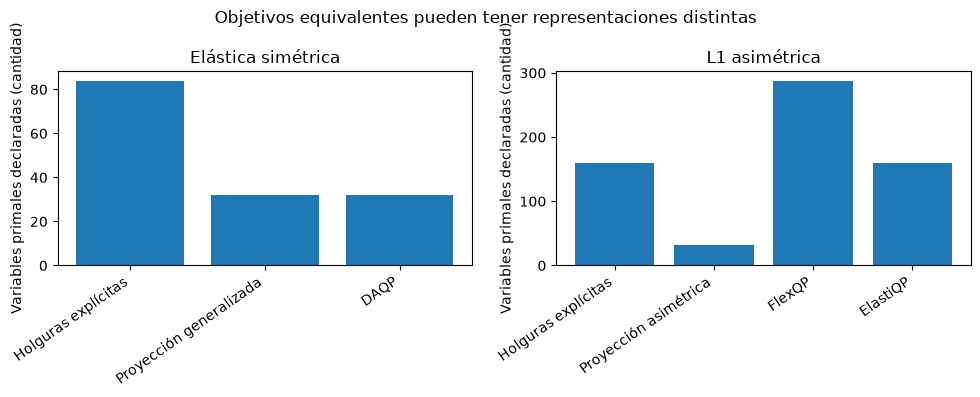

In [9]:
# Comparar representación dentro de una familia, nunca objetivos entre familias.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, results, title in zip(axes, [elastic_results, l1_results], ["Elástica simétrica", "L1 asimétrica"]):
    labels = [method_labels[r["method"]] for r in results]
    ax.bar(labels, [r["dimensions"]["variables"] for r in results])
    ax.set(title=title, ylabel="Variables primales declaradas (cantidad)")
    ax.tick_params(axis="x", rotation=35)
    plt.setp(ax.get_xticklabels(), ha="right")
fig.suptitle("Objetivos equivalentes pueden tener representaciones distintas")
fig.tight_layout()
plt.show()


Los paneles muestran diferencias de formulación después de verificar concordancia, sin declarar ganador a la barra menor. Algunas referencias usan holguras por lado y la proyección generalizada conserva la dimensión original. Las estructuras internas densas y la reducción de Schur no se deducen directamente de estos conteos. La figura respalda una afirmación de representación; la campaña pareada registrada aporta por separado la evidencia computacional.


Finalmente aislamos la penalización exacta en el caso escalar superior. El óptimo duro es x=1 y su multiplicador es 2 con curvatura unitaria y objetivo 3. Un peso lineal al menos igual a ese multiplicador puede recuperar el óptimo duro; uno menor compra incumplimiento. Variamos solo el precio lineal superior y ejecutamos tres implementaciones L1 en cada valor.


In [10]:
# El umbral depende del multiplicador del problema, no de un peso mágico universal.
weights = np.array([0.2, 0.5, 1.2, 3.0, 6.0])
curves = {"asymmetric": [], "flex": [], "elastiqp": []}
for weight in weights:
    source = scalar(3.0, asymmetric=True)
    penalty = replace(source.penalty, upper_linear=np.array([weight]),
                      lower_quadratic=np.zeros(1), upper_quadratic=np.zeros(1))
    priced = replace(source, penalty=penalty)
    curves["asymmetric"].append(solve(priced, "asymmetric", **native_settings)["x"][0])
    curves["flex"].append(solve_flex(priced, **settings)["x"][0])
    curves["elastiqp"].append(solve_elastiqp(priced, **settings)["x"][0])
print(f"Decisión con precio superior 1.2: {curves['asymmetric'][2]:.6f}")


Decisión con precio superior 1.2: 1.800000


Graficamos decisión frente a precio para separar concordancia de solvers y comportamiento de política. Curvas superpuestas respaldan el mismo óptimo L1 dentro de tolerancia. El segmento plano en el óptimo duro aparece tras el umbral particular. El ejemplo explica por qué una formulación elástica siempre resoluble no necesita satisfacer la desigualdad dura original si se elige un precio bajo.


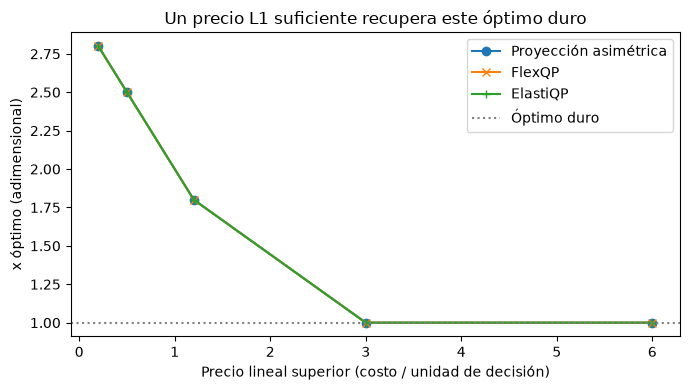

In [11]:
# Distintas marcas muestran concordancia sin mezclar unidades ni objetivos.
fig, ax = plt.subplots(figsize=(7, 4))
for (name, values), marker in zip(curves.items(), ["o", "x", "+"]):
    ax.plot(weights, values, marker=marker, label=method_labels[name])
ax.axhline(1.0, color="gray", linestyle=":", label="Óptimo duro")
ax.set(xlabel="Precio lineal superior (costo / unidad de decisión)", ylabel="x óptimo (adimensional)",
       title="Un precio L1 suficiente recupera este óptimo duro")
ax.legend()
fig.tight_layout()
plt.show()


Con precios bajos, los tres métodos prefieren un punto exterior. Con precios suficientes alcanzan el límite superior. Concordar no convierte la solución barata en factible dura ni demuestra una constante universal para otros QP. Acoplamiento, curvatura y escala modifican los multiplicadores óptimos. Es una lección de penalización exacta sobre un problema escalar declarado, no una certificación de política aprendida.


### Úsalo con tus propios datos

Antes de admitir otra instancia dispersa, registre familia de penalización, lados finitos, máscara dura, dimensiones e hipótesis de convexidad junto con las matrices. La llamada a `generated_problem` usa una semilla de desarrollo declarada y normalización de filas; no extrae una muestra de la población reservada del estudio. Para datos de aplicación construya un `Problem` con sus coeficientes reales y examine unidades y precios antes de escoger método. No convierta una desigualdad dura en un precio finito sólo para ejecutar un solucionador incompatible.

El índice científico leído conserva `default_case`, `cases`, `environment`, `state` y `limitations`. Cada entrada liga una ruta relativa de resultado con su SHA-256. El índice exterior de despliegue aporta `files`, rutas de manifiesto, `n_cases` y `engine_version`. A su vez, el manifiesto de caso identifica el artefacto mediante ruta, bytes y resumen, y registra `lane`, identidad del motor y puerta de aceptación. Esas capas indican qué datos se desplegaron, qué caso representan y cómo identificar sus bytes. No certifican que un método mostrado como rápido haya resuelto el mismo objetivo.

El índice experimental enumera `protocol_id`, `state` y `artifacts`, cada uno con esquema, bytes y resumen. La tabla de conjuntos mantiene `id`, `split`, `n`, `density`, `condition`, `family`, `seed`, `problem_sha256` y resultado del oráculo. Un ensayo conserva esa identidad junto con `method`, `repetition`, `warmup`, `state`, `reason`, `metrics`, `normalized_gap` y tiempos separados de resolución, actualización y preparación. Una métrica ausente en un ensayo incompatible tiene significado: convertirla a cero inventaría una comparación perfecta. El primer ensayo leído ilustra ese rechazo sin sustituir las comparaciones que acabamos de ejecutar.

El procesamiento determinista construye las entradas, evalúa candidatos en coordenadas originales y exporta todos los estados. No tiene una operación de entrenamiento ni un modelo ajustado para estos solucionadores; la política aprendida de Deep FlexQP continúa no disponible. La operación de inferencia aquí es resolución matemática, no predicción con un sustituto sin entrenar. Al extender el procesamiento, conserve la decisión de compatibilidad antes de ejecutar y la aceptación original después, manteniendo fallas y valores ausentes durante la exportación. De ese modo un consumidor puede reconstruir denominadores y no recibe un ranking que haya borrado sus casos difíciles.


In [12]:
# Los índices y el rechazo guardado explican contratos, no sustituyen las decisiones nuevas.
print('Índice científico', scientific_index["schema_version"], sorted(scientific_index["cases"][0]))
print('Despliegue y manifiesto', deployment_index["schema"], manifest_example["schema"],
      sorted(manifest_example["artifact"]))
print('Índice experimental', experiment_index["schema_version"], sorted(experiment_index["artifacts"][0]))
print('Campos del conjunto', sorted(datasets[0]))
print('Primer ensayo guardado', first_trial["state"], first_trial["reason"], first_trial["metrics"])


Índice científico softqp.index/v1 ['case_id', 'category', 'failed', 'path', 'sha256', 'title']
Despliegue y manifiesto softqp.artifact-index/v1 softqp.manifest/v1 ['bytes', 'format', 'path', 'sha256']
Índice experimental softqp.experiments/v1 ['bytes', 'path', 'schema', 'sha256']
Campos del conjunto ['condition', 'density', 'family', 'generation_seconds', 'id', 'n', 'oracle_objective', 'oracle_reason', 'oracle_state', 'problem_sha256', 'seed', 'split']
Primer ensayo guardado incompatible FlexQP reconstruction relaxes its inequalities; original hard rows are not softened None


### Sensibilidad y límites de esta comparación

El barrido escalar anterior cambia la política de optimización, no la tolerancia. En el óptimo duro superior $x=1$, la derivada sin precio es $1-3=-2$, por lo que el multiplicador particular vale dos. Un precio lineal positivo menor compra incumplimiento; al alcanzar el umbral se recupera el mínimo duro en este caso estrictamente convexo. La cifra cambia con curvatura, escala de fila y acoplamiento: no es una constante transferible a control o energía.

La tercera figura compara las decisiones recuperadas contra el levantamiento independiente dentro de cada familia dispersa. Complementa la comparación de objetivos: dos puntos pueden tener costos próximos y diferir en direcciones poco curvadas. El eje logarítmico simétrico conserva el cero exacto en lugar de inventar un error positivo mínimo para dibujarlo. Las diferencias son diagnósticos numéricos con las tolerancias indicadas, no intervalos de confianza. Una afirmación temporal requeriría el protocolo pareado, repeticiones y fallas retenidas del estudio registrado, que esta ejecución didáctica no reemplaza.


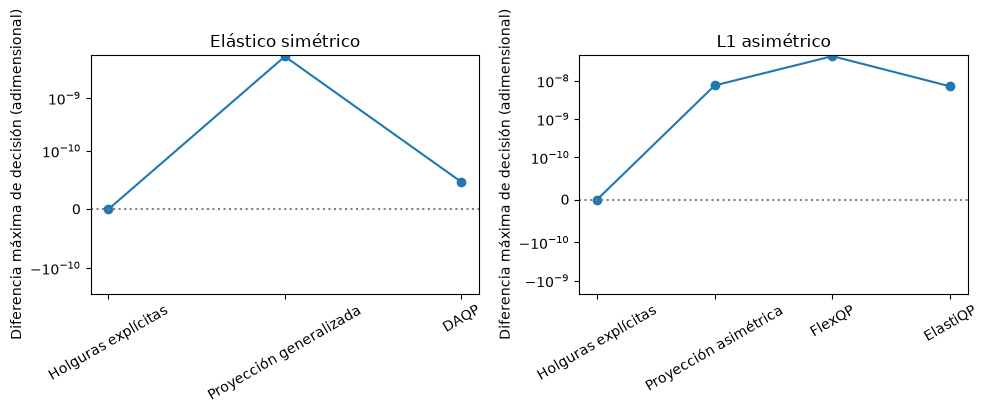

In [13]:
# Comparar decisiones dentro de cada familia conserva una referencia independiente.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
families = [elastic_results, l1_results]
references = [elastic_lift, l1_lift]
titles = ['Elástico simétrico', 'L1 asimétrico']
for ax, results, reference, title in zip(axes, families, references, titles):
    errors = [np.max(np.abs(np.asarray(r["x"]) - reference["x"])) for r in results]
    ax.plot([method_labels[r["method"]] for r in results], errors, marker="o")
    ax.axhline(0, color="gray", linestyle=":")
    ax.set_yscale("symlog", linthresh=1e-10)
    ax.set(ylabel='Diferencia máxima de decisión (adimensional)', title=title)
    ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()


Los paneles mantienen familias matemáticas separadas y cada una conserva su propia referencia levantada. Diferencias pequeñas apoyan acuerdo en estas instancias generadas sin ocultar las hipótesis de cada solucionador. La línea de cero es exacta y la zona cercana es lineal, por lo que una diferencia nula no recibe un piso artificial. La figura no identifica el método más rápido ni extiende ElastiQP o FlexQP fijo a desigualdades duras o costos blandos cuadráticos no admitidos.


## Resultados

**Respuesta:** Con precio lineal superior 1.2, el óptimo escalar L1 puro es 1.800000, distinto del 1.160000 elástico. Ese cambio corresponde a otro objetivo. Dentro de cada familia dispersa, las brechas originales y los diagnósticos proximales cuantifican concordancia entre métodos compatibles y sus holguras independientes. Las figuras distinguen dimensiones de política y no clasifican tiempos.

Deep FlexQP sigue documentado como comparador no disponible. No se fabricó un resultado aprendido y la reconstrucción fija no se presenta como reproducción de su aceleración entrenada.


## Resumen

Primero iguale objetivo, lados finitos, política dura y unidades; después interprete estados y recupere signos duales. Conserve las incompatibilidades. Solo entonces tiene sentido un protocolo computacional común. La próxima lección evalúa una propuesta, incluida la posibilidad de que matemática correcta y matrices menores no produzcan una reducción temporal útil.


## Referencias

- [Proyecciones generalizadas](https://arxiv.org/abs/2610.35631).
- [Pesos blandos originales de DAQP](https://darnstrom.github.io/daqp/start/advanced/soft).
- [Oshin y colaboradores, ecuaciones FlexQP y Algoritmo 1](https://arxiv.org/html/2512.01565v2).
- [Implementación publicada ElastiQP](https://github.com/StanfordASL/elastiqp).

- [OSQP formulation and residuals](https://osqp.org/docs/solver/).
- [SoftQP matched-objective technical report](https://doi.org/10.5281/zenodo.23851659).
